# **Lab 7(B) - Mathematical and Statistical Filters (Colored Image)**

This is the colored-image version of the Lab 7(B) notebook. 

**What changed compared with the grayscale notebook**
- The image is loaded in **color** (`cv2.imread(file)` instead of `cv2.imread(file, 0)`), so every array is `height x width x 3` (B, G, R).
- `add_noise` used `row, col = image.shape`, which fails for 3 channels. It now uses `image.shape[:2]`, and noise is generated for every color channel.
- **Salt & pepper** noise now sets *all three channels* of a pixel, so the noise shows up as pure white and pure black dots (not random colored specks). The amount is computed from `row * col` (number of pixels) so the density matches the grayscale version.
- `cv2.blur`, `cv2.filter2D`, `cv2.medianBlur`, `cv2.dilate` and `cv2.erode` all process each color channel independently, so the filters themselves work unchanged.
- OpenCV stores color as **BGR**, so every image is converted to **RGB** before being shown with matplotlib.
- A random seed is set so the noisy images are the same every time you run the notebook.
- The salt & pepper image is used for the Contra-Harmonic, Median and Max/Min sections, since those filters are designed for salt & pepper noise (the original notebook's titles say so). You can switch `noise_img` in any cell to try the other noise types.

### Step 0: Install packages and download the colored sample image 

In [1]:
%pip install -q opencv-python numpy matplotlib

import os

images_dir = os.path.join(os.getcwd(), 'images')
os.makedirs(images_dir, exist_ok=True)

# A colored sample image (the same parrot image used in earlier labs)
url = 'https://raw.githubusercontent.com/PacktPublishing/Hands-On-Image-Processing-with-Python/master/images/parrot.png'
dest = os.path.join(images_dir, 'Parrot.png')

!curl -L -s -o "{dest}" "{url}"
size = os.path.getsize(dest) if os.path.exists(dest) else 0
print(f'Parrot.png: {"OK" if size > 0 else "FAILED"} ({size} bytes) -> {dest}')

Note: you may need to restart the kernel to use updated packages.
Parrot.png: OK (215272 bytes) -> c:\Users\dania\Image_Processing_Labs\Lab7\images\Parrot.png


In [2]:
import cv2
import numpy as np

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)

# OpenCV loads color images as BGR, but matplotlib expects RGB -> reverse the channel order for display
def rgb(img):
    return img[:, :, ::-1]

# Scale any array (e.g. a Laplacian with negative values) to 0..1 so it can be displayed in color
def norm01(a):
    a = a.astype(np.float64)
    return (a - a.min()) / (a.max() - a.min() + 1e-12)

Image shape: (340, 453, 3)


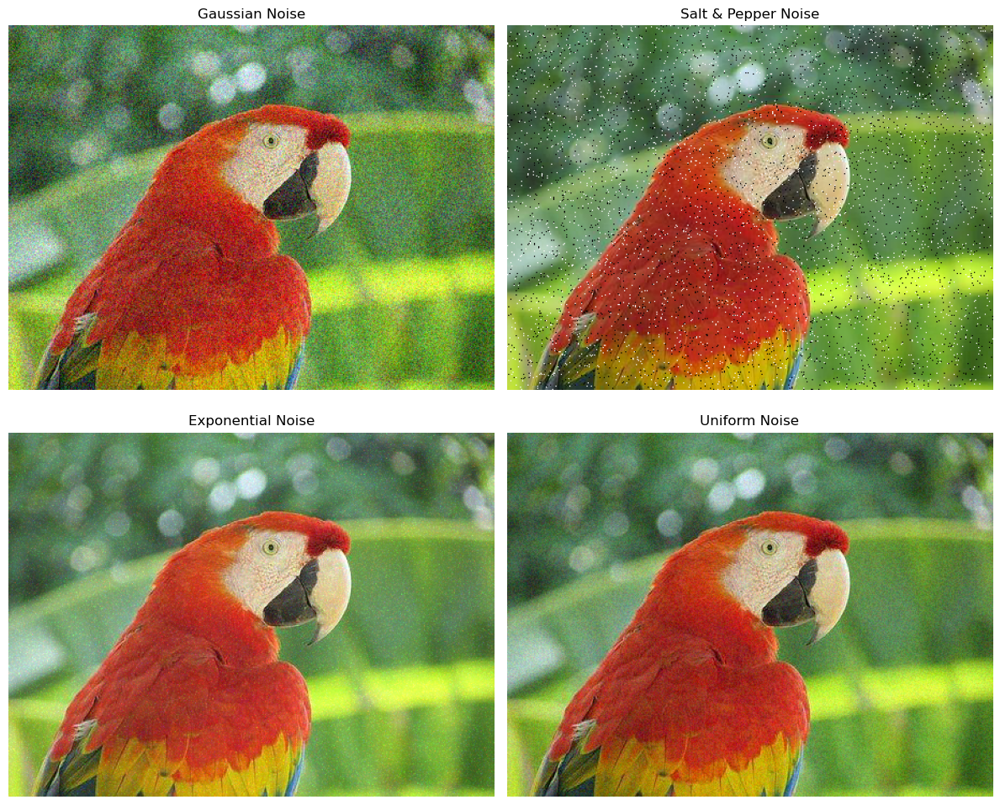

In [3]:
# ========== ( Adding noise to an Image ) =================

np.random.seed(42)  # same noise every run

# 0. Read an Image (in COLOR)
imgPath = os.path.join('images', 'Parrot.png')   # change this to use your own colored image
img = cv2.imread(imgPath, cv2.IMREAD_COLOR)
print('Image shape:', img.shape)

# 1. Function that handle all noise algorithm (Gaussian, Exp, Uniform & Salt&Pepper)
def add_noise(image, noise_type):
    row, col = image.shape[:2]          # works for both grayscale and color images

    if noise_type == "gaussian":
        mean = 0
        var = 0.01  # Adjust for more/less noise
        sigma = var**0.5
        gauss = np.random.normal(mean, sigma, image.shape)   # independent noise for every channel
        noisy = image / 255 + gauss
        return np.clip(noisy * 255, 0, 255).astype(np.uint8)

    elif noise_type == "salt_pepper":
        s_vs_p = 0.5
        amount = 0.04
        noisy = np.copy(image)
        # Salt (white pixels) - amount is based on the number of PIXELS (row * col), not the number of values
        num_salt = int(np.ceil(amount * row * col * s_vs_p))
        ys = np.random.randint(0, row, num_salt)
        xs = np.random.randint(0, col, num_salt)
        noisy[ys, xs] = 255             # sets B, G and R -> pure white pixel
        # Pepper (black pixels)
        num_pepper = int(np.ceil(amount * row * col * (1.0 - s_vs_p)))
        ys = np.random.randint(0, row, num_pepper)
        xs = np.random.randint(0, col, num_pepper)
        noisy[ys, xs] = 0               # sets B, G and R -> pure black pixel
        return noisy

    elif noise_type == "exponential":
        # Scale is the inverse of the rate (lambda)
        expo = np.random.exponential(scale=10.0, size=image.shape)
        noisy = image + expo
        return np.clip(noisy, 0, 255).astype(np.uint8)

    elif noise_type == "uniform":
        low = -20
        high = 20
        uni = np.random.uniform(low, high, image.shape)
        noisy = image + uni
        return np.clip(noisy, 0, 255).astype(np.uint8)

    else:
        raise ValueError(f"Unknown noise type: {noise_type}")


# 2. Generate Noisy Images
noise_gauss = add_noise(img, "gaussian")
noise_sp = add_noise(img, "salt_pepper")
noise_expo = add_noise(img, "exponential")
noise_uni = add_noise(img, "uniform")

# 3. Display in 2x2 Grid
plt.figure(figsize=(12, 10))

plt.subplot(221), plt.imshow(rgb(noise_gauss)), plt.title('Gaussian Noise')
plt.subplot(222), plt.imshow(rgb(noise_sp)), plt.title('Salt & Pepper Noise')
plt.subplot(223), plt.imshow(rgb(noise_expo)), plt.title('Exponential Noise')
plt.subplot(224), plt.imshow(rgb(noise_uni)), plt.title('Uniform Noise')

for ax in plt.gcf().axes: ax.axis('off')

plt.tight_layout()
plt.show()

## **Arithmetic Mean Filter**

Max difference between the two methods: 0


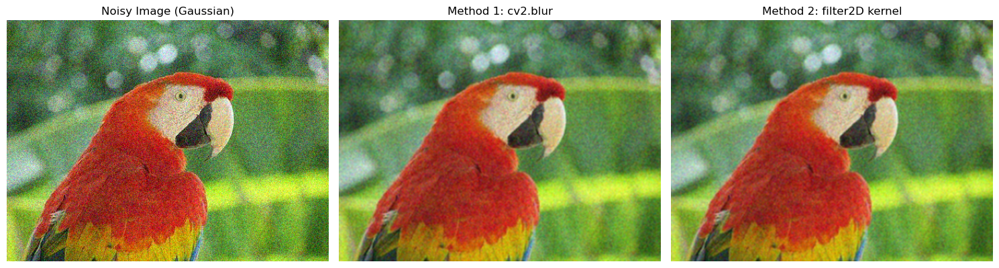

In [4]:
# --- METHOD 1: Using Built-in OpenCV function ---

# Apply Arithmetic Mean Filter (using a 3x3 blur window)
# The larger the numbers in (3, 3), the smoother the image becomes,
# you can change kernel size to (5,5), (7,7) etc.
filtered_img = cv2.blur(noise_gauss, (3, 3))

# --- METHOD 2: Manual implementation using a Kernel ---

# An Arithmetic Mean kernel is just a matrix of 1s divided by the total number of pixels.
kernel_size = 3
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
arithmetic_mean_manual = cv2.filter2D(noise_gauss, -1, kernel)

# Both methods should give (almost) the same result
print('Max difference between the two methods:', np.max(np.abs(filtered_img.astype(int) - arithmetic_mean_manual.astype(int))))

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(rgb(noise_gauss)), plt.title('Noisy Image (Gaussian)')
plt.subplot(132), plt.imshow(rgb(filtered_img)), plt.title('Method 1: cv2.blur')
plt.subplot(133), plt.imshow(rgb(arithmetic_mean_manual)), plt.title('Method 2: filter2D kernel')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

## **Geometric Means**

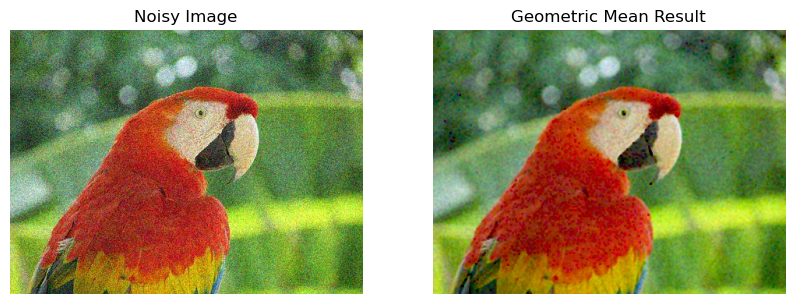

In [5]:
def geometric_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 and add a tiny epsilon to avoid log(0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Apply the log-transform
    log_img = np.log(img_float)

    # 3. Apply a box filter to the log image (calculates the average of logs) - done per color channel
    kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
    mean_log = cv2.filter2D(log_img, -1, kernel)

    # 4. Take the exponent to get back to the geometric mean
    geo_mean = np.exp(mean_log)

    # 5. Clip and convert back to 8-bit
    return np.clip(geo_mean, 0, 255).astype(np.uint8)


# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss

# Apply filter
result = geometric_mean_filter(noise_img, kernel_size=3)

# Display Comparison
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(rgb(noise_img)), plt.title('Noisy Image')
plt.subplot(122), plt.imshow(rgb(result)), plt.title('Geometric Mean Result')
for ax in plt.gcf().axes: ax.axis('off')
plt.show()

## **Harmonic Means Filter**

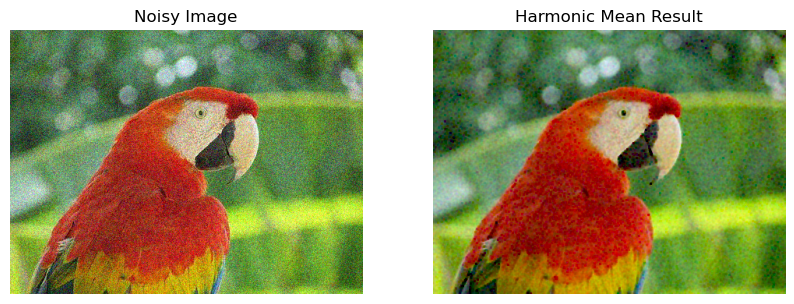

In [6]:
def harmonic_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 to avoid overflow during calculation
    # Add a tiny epsilon to handle black pixels (0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Calculate the reciprocal of every pixel (1/P)
    reciprocal_img = 1.0 / img_float

    # 3. Sum the reciprocals in a window (per color channel)
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    sum_reciprocal = cv2.filter2D(reciprocal_img, -1, kernel)

    # 4. Final step of the formula: (Window Size) / Sum of Reciprocals
    # Note: Window size is kernel_size * kernel_size
    n = kernel_size * kernel_size
    harmonic_mean = n / sum_reciprocal

    # 5. Clip the results and convert back to 8-bit
    return np.clip(harmonic_mean, 0, 255).astype(np.uint8)


# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss

# Apply the filter
cleaned_img = harmonic_mean_filter(noise_img, kernel_size=3)

# Display Comparison
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(rgb(noise_img)), plt.title('Noisy Image')
plt.subplot(122), plt.imshow(rgb(cleaned_img)), plt.title('Harmonic Mean Result')
for ax in plt.gcf().axes: ax.axis('off')
plt.show()

## **Contra - Harmonic Mean Filter**

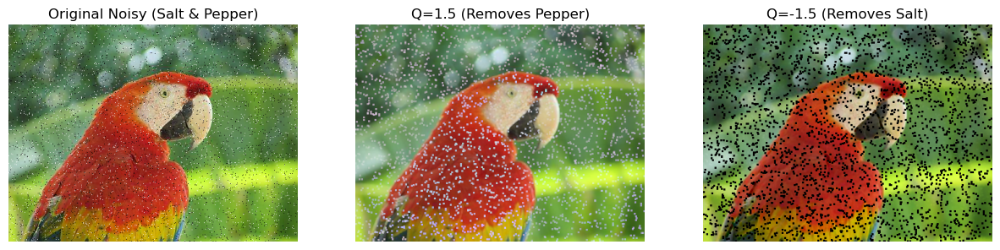

In [7]:
def contra_harmonic_mean(image, kernel_size=3, Q=0):
    # 1. Convert to float to handle high powers and prevent overflow
    img_float = image.astype(np.float64) + 1e-6

    # 2. Calculate numerator: Sum of pixels to the power (Q + 1)
    numerator = np.power(img_float, Q + 1)
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    num_sum = cv2.filter2D(numerator, -1, kernel)

    # 3. Calculate denominator: Sum of pixels to the power (Q)
    denominator = np.power(img_float, Q)
    den_sum = cv2.filter2D(denominator, -1, kernel)

    # 4. Divide and clean up
    # Handle potential division by zero
    result = num_sum / (den_sum + 1e-6)

    return np.clip(result, 0, 255).astype(np.uint8)

# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_sp   # salt & pepper noise, which is what this filter is designed for

# --- APPLICATIONS ---
# Q > 0 (e.g., 1.5): Removes Pepper Noise (black spots)
pepper_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=1.5)

# Q < 0 (e.g., -1.5): Removes Salt Noise (white spots)
salt_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=-1.5)

# --- DISPLAY ---
plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(rgb(noise_img)), plt.title('Original Noisy (Salt & Pepper)')
plt.subplot(132), plt.imshow(rgb(pepper_removed)), plt.title('Q=1.5 (Removes Pepper)')
plt.subplot(133), plt.imshow(rgb(salt_removed)), plt.title('Q=-1.5 (Removes Salt)')
for ax in plt.gcf().axes: ax.axis('off')
plt.show()

## **Median Filter**

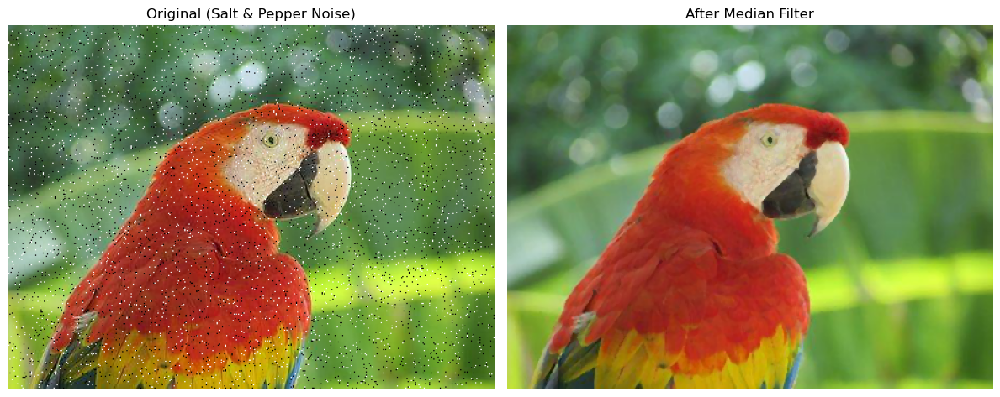

In [8]:
# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_sp   # salt & pepper noise

# 2. Apply Median Filter (on each color channel)
# The second argument is the 'ksize' (kernel size).
# It MUST be an odd integer (3, 5, 7, etc.)
median_result = cv2.medianBlur(noise_img, 3)

# 3. Compare Results
plt.figure(figsize=(12, 6))

plt.subplot(121), plt.imshow(rgb(noise_img)), plt.title('Original (Salt & Pepper Noise)'), plt.axis('off')
plt.subplot(122), plt.imshow(rgb(median_result)), plt.title('After Median Filter'), plt.axis('off')
plt.tight_layout()
plt.show()

## **Max and Min Filter**

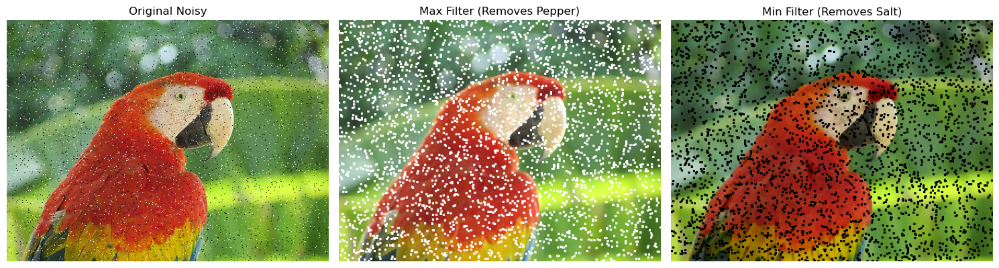

In [9]:
# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_sp   # salt & pepper noise


# 2. Define the Kernel size (e.g., 3x3)
kernel = np.ones((3, 3), np.uint8)

# 3. Apply Max Filter (Dilation)
# This picks the brightest pixel in the neighborhood (per color channel).
max_filter = cv2.dilate(noise_img, kernel)

# 4. Apply Min Filter (Erosion)
# This picks the darkest pixel in the neighborhood (per color channel).
min_filter = cv2.erode(noise_img, kernel)

# --- Display Results ---
plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(rgb(noise_img)), plt.title('Original Noisy')
plt.subplot(132), plt.imshow(rgb(max_filter)), plt.title('Max Filter (Removes Pepper)')
plt.subplot(133), plt.imshow(rgb(min_filter)), plt.title('Min Filter (Removes Salt)')

for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

## **Mid-Point Filtering**

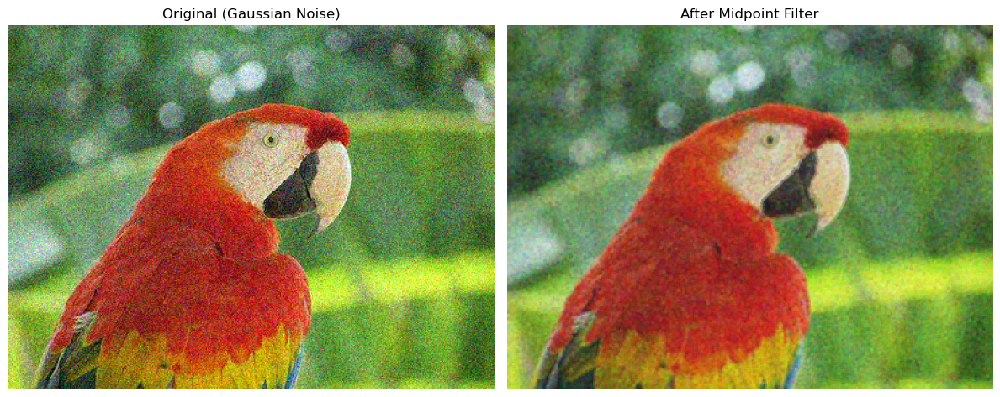

In [10]:
def midpoint_filter(image, kernel_size=3):
    # 1. Define the structural element (kernel)
    kernel = np.ones((kernel_size, kernel_size), np.uint8)

    # 2. Find the Maximum value in the neighborhood (Dilation)
    max_img = cv2.dilate(image, kernel).astype(np.float64)

    # 3. Find the Minimum value in the neighborhood (Erosion)
    min_img = cv2.erode(image, kernel).astype(np.float64)

    # 4. Calculate the average of Max and Min
    midpoint = (max_img + min_img) / 2

    # 5. Convert back to 8-bit
    return midpoint.astype(np.uint8)



# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss


# Apply the Midpoint Filter
result = midpoint_filter(noise_img, kernel_size=3)

# --- Display Results ---
plt.figure(figsize=(12, 6))

plt.subplot(121), plt.imshow(rgb(noise_img)), plt.title('Original (Gaussian Noise)'), plt.axis('off')
plt.subplot(122), plt.imshow(rgb(result)), plt.title('After Midpoint Filter'), plt.axis('off')

plt.tight_layout()
plt.show()